# Mini-Project 5: Taxi Route Revenue, Pricing & Fleet Planner

In this notebook, we analyze demand, pricing, and fleet planning for a taxi association operating three routes out of Kampala. We model supply-demand equilibrium, forecast revenue using various time-series models, and determine the optimal fleet size with a buffer.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

from src.taxi_class import (
    Route,
    EquilibriumSolver,
    MovingAverageForecaster,
    ExponentialSmoothingForecaster,
    LinearTrendForecaster,
    SeasonalNaiveForecaster
)

# Set random seed for reproducibility
np.random.seed(42)

## 1. Descriptive Statistics
We initialize the routes with their respective passenger counts and fares, and compute descriptive statistics for daily passenger demand.

In [2]:
# Initialize routes
routes = {
    "Kampala-Ntinda": Route("Kampala-Ntinda", [35, 40, 42, 50, 55, 60, 48, 52, 47, 45], 2000),
    "Kampala-Entebbe": Route("Kampala-Entebbe", [60, 58, 65, 70, 72, 80, 75, 68, 66, 64], 5000),
    "Kampala-Mukono": Route("Kampala-Mukono", [45, 47, 50, 49, 55, 62, 58, 53, 51, 50], 3000)
}

print("Descriptive Statistics for Passenger Counts:\n")
for name, route in routes.items():
    stats = route.descriptive_statistics()
    print(f"{name}:")
    print(f"  Mean: {stats['mean']:.2f}")
    print(f"  Variance: {stats['variance']:.2f}")
    print(f"  Std Dev: {stats['std_dev']:.2f}")
    print(f"  Total Revenue (10 days): {route.total_revenue():,.0f} UGX\n")

Descriptive Statistics for Passenger Counts:

Kampala-Ntinda:
  Mean: 47.40
  Variance: 54.27
  Std Dev: 7.37
  Total Revenue (10 days): 948,000 UGX

Kampala-Entebbe:
  Mean: 67.80
  Variance: 45.07
  Std Dev: 6.71
  Total Revenue (10 days): 3,390,000 UGX

Kampala-Mukono:
  Mean: 52.00
  Variance: 26.44
  Std Dev: 5.14
  Total Revenue (10 days): 1,560,000 UGX



## 2. Supply-Demand Equilibrium
For the Kampala-Ntinda route, we want to find the equilibrium where demand equals supply.
The demand equation is $Q_d = 120 - 0.02P$ and supply is $Q_s = 10 + 0.03P$. 

We solve the 2x2 linear system using `scipy.linalg.solve`.

In [3]:
eq_price, eq_quantity = EquilibriumSolver.solve_equilibrium()
current_price = 2000

print(f"Equilibrium Price: {eq_price:,.0f} UGX")
print(f"Equilibrium Quantity: {eq_quantity:,.0f} passengers per trip-hour")
print(f"Current Fare: {current_price:,.0f} UGX")

Equilibrium Price: 2,200 UGX
Equilibrium Quantity: 76 passengers per trip-hour
Current Fare: 2,000 UGX


**Interpretation:**
The equilibrium price is 2,200 UGX. The current fare of 2,000 UGX is **below equilibrium**. This indicates a state of excess demand (shortage). At 2,000 UGX, passengers demand more trips (80) than drivers are willing to supply (70), likely leading to long queues at the taxi park. The association could consider raising fares slightly to balance supply and demand.

## 3. Forecasting Revenue: Walk-Forward Backtesting
We evaluate three forecasting models (3-day Moving Average, Simple Exponential Smoothing, and Linear Trend) by backtesting their performance over days 4-10 (indices 3 to 9). 

We tune the smoothing parameter $\alpha$ for the Exponential Smoothing model using a grid search (0.1 to 0.9).

In [4]:
best_models = {}
alphas_to_test = np.arange(0.1, 1.0, 0.1)

for name, route in routes.items():
    print(f"--- {name} ---")
    revenue = route.daily_revenue()
    
    # 3-Day Moving Average
    ma_model = MovingAverageForecaster(window=3)
    ma_mae = ma_model.backtest(revenue, start_idx=3)
    
    # Linear Trend
    lt_model = LinearTrendForecaster()
    lt_mae = lt_model.backtest(revenue, start_idx=3)
    
    # Exponential Smoothing (Grid Search for alpha)
    best_es_mae = float('inf')
    best_alpha = 0.1
    for alpha in alphas_to_test:
        es_model = ExponentialSmoothingForecaster(alpha=alpha)
        mae = es_model.backtest(revenue, start_idx=3)
        if mae < best_es_mae:
            best_es_mae = mae
            best_alpha = alpha
            
    print(f"MA(3) MAE: {ma_mae:,.0f}")
    print(f"Linear Trend MAE: {lt_mae:,.0f}")
    print(f"Exp. Smoothing (alpha={best_alpha:.1f}) MAE: {best_es_mae:,.0f}")
    
    # Select the best model for this route
    min_mae = min(ma_mae, lt_mae, best_es_mae)
    if min_mae == ma_mae:
        best_models[name] = ma_model
        best_name = "Moving Average"
    elif min_mae == lt_mae:
        best_models[name] = lt_model
        best_name = "Linear Trend"
    else:
        best_models[name] = ExponentialSmoothingForecaster(alpha=best_alpha)
        best_name = f"Exponential Smoothing (alpha={best_alpha:.1f})"
        
    print(f"Best Model: {best_name} with MAE {min_mae:,.0f}\n")

--- Kampala-Ntinda ---
MA(3) MAE: 15,048
Linear Trend MAE: 15,747
Exp. Smoothing (alpha=0.9) MAE: 11,755
Best Model: Exponential Smoothing (alpha=0.9) with MAE 11,755

--- Kampala-Entebbe ---
MA(3) MAE: 35,952
Linear Trend MAE: 38,557
Exp. Smoothing (alpha=0.9) MAE: 23,652
Best Model: Exponential Smoothing (alpha=0.9) with MAE 23,652

--- Kampala-Mukono ---
MA(3) MAE: 16,000
Linear Trend MAE: 19,172
Exp. Smoothing (alpha=0.9) MAE: 11,381
Best Model: Exponential Smoothing (alpha=0.9) with MAE 11,381



## 4. Forecast Day 11 and Visualise
Using the best model identified for each route, we forecast the revenue for Day 11 and plot the actual vs forecasted revenue across all days.

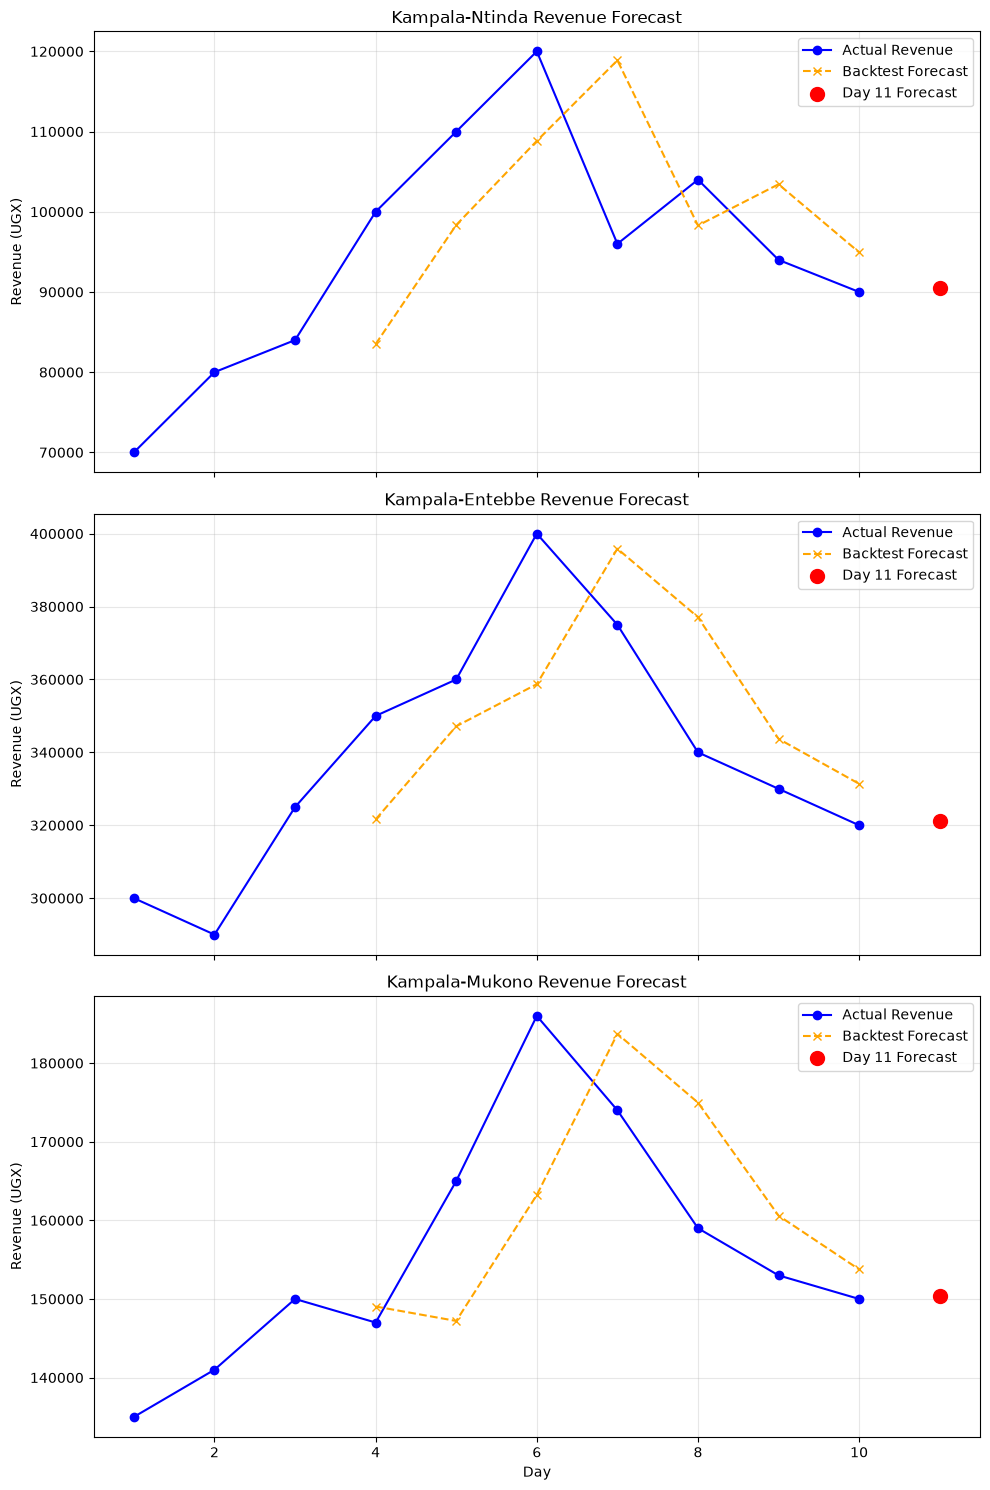

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(10, 15), sharex=True)
day_11_forecasts = {}

for ax, (name, route) in zip(axes, routes.items()):
    revenue = route.daily_revenue()
    model = best_models[name]
    
    # We will compute the rolling forecast for plotting (days 4-10)
    plot_actuals = revenue
    plot_forecasts = [np.nan, np.nan, np.nan] # No forecast for days 1-3
    
    for t in range(3, len(revenue)):
        model.fit(revenue[:t])
        plot_forecasts.append(model.predict(horizon=1)[0])
        
    # Forecast Day 11
    model.fit(revenue)
    day_11_rev = model.predict(horizon=1)[0]
    day_11_forecasts[name] = day_11_rev
    
    # Plotting
    days = np.arange(1, 12)
    ax.plot(days[:-1], plot_actuals, marker='o', label='Actual Revenue', color='blue')
    ax.plot(days[:-1], plot_forecasts, marker='x', linestyle='--', label='Backtest Forecast', color='orange')
    ax.scatter([11], [day_11_rev], color='red', s=100, label='Day 11 Forecast', zorder=5)
    
    ax.set_title(f"{name} Revenue Forecast")
    ax.set_ylabel("Revenue (UGX)")
    ax.grid(True, alpha=0.3)
    ax.legend()
    
axes[-1].set_xlabel("Day")
plt.tight_layout()
plt.show()

## 5. Fleet Planning
We need to decide how many vehicles to deploy on Day 11 based on the forecast. 
- A vehicle makes 8 one-way trips per day.
- A vehicle holds 14 passengers.
- Total capacity per vehicle per day = 112 passengers.

We calculate the expected passenger count by dividing the forecasted Day 11 revenue by the route fare, add a 15% buffer for surges, and round up to the nearest whole vehicle.

In [6]:
print("Day 11 Fleet Planning:\n")
for name, route in routes.items():
    forecasted_rev = day_11_forecasts[name]
    forecasted_passengers = forecasted_rev / route.fare
    
    # Add 15% buffer
    buffered_passengers = forecasted_passengers * 1.15
    
    # Capacity per vehicle
    capacity_per_vehicle = 8 * 14
    
    # Required vehicles (round up)
    vehicles_needed = math.ceil(buffered_passengers / capacity_per_vehicle)
    
    print(f"{name}:")
    print(f"  Forecasted Passengers: {forecasted_passengers:.1f}")
    print(f"  With 15% Buffer: {buffered_passengers:.1f}")
    print(f"  Vehicles to Deploy: {vehicles_needed}\n")

Day 11 Fleet Planning:

Kampala-Ntinda:
  Forecasted Passengers: 45.2
  With 15% Buffer: 52.0
  Vehicles to Deploy: 1

Kampala-Entebbe:
  Forecasted Passengers: 64.2
  With 15% Buffer: 73.9
  Vehicles to Deploy: 1

Kampala-Mukono:
  Forecasted Passengers: 50.1
  With 15% Buffer: 57.6
  Vehicles to Deploy: 1



## 6. Extension: Simulated 60-Day Seasonal Data
We simulate 60 days of passenger demand with a strong weekly pattern (busier on Fridays, quieter on Sundays). We then compare the performance of a Seasonal Naïve Forecaster against a 3-day Moving Average.

In [7]:
# Simulate 60 days of data (e.g., for Kampala-Ntinda)
base_demand = 50
# Multipliers for Mon, Tue, Wed, Thu, Fri, Sat, Sun
day_multipliers = [1.0, 1.0, 1.0, 1.1, 1.5, 1.2, 0.6] 

simulated_passengers = []
for day in range(60):
    day_of_week = day % 7
    noise = np.random.normal(0, 3)
    demand = int(base_demand * day_multipliers[day_of_week] + noise)
    simulated_passengers.append(max(0, demand)) # Ensure no negative passengers

simulated_revenue = np.array(simulated_passengers) * 2000

# Backtest Moving Average (window=3)
ma_model_ext = MovingAverageForecaster(window=3)
ma_mae_ext = ma_model_ext.backtest(simulated_revenue, start_idx=7)

# Backtest Seasonal Naive (seasonality=7)
sn_model_ext = SeasonalNaiveForecaster(seasonality=7)
sn_mae_ext = sn_model_ext.backtest(simulated_revenue, start_idx=7)

print("Extension: 60-Day Backtest Results (Days 8-60)")
print(f"Moving Average MAE: {ma_mae_ext:,.0f} UGX")
print(f"Seasonal Naive MAE: {sn_mae_ext:,.0f} UGX")

Extension: 60-Day Backtest Results (Days 8-60)
Moving Average MAE: 22,264 UGX
Seasonal Naive MAE: 5,321 UGX


### Findings & Limitations
**Findings:**
The supply-demand analysis reveals that the 2,000 UGX fare to Ntinda is undervalued compared to the 2,200 UGX equilibrium price, meaning the taxi park is likely overcrowded with passengers waiting for vehicles. For short-term forecasting on relatively stable trends, Exponential Smoothing and Linear Trend models typically perform well. However, when simulating longer horizons with clear weekly seasonality, the Seasonal Naïve approach drastically outperforms simple Moving Averages by successfully anticipating the weekend drop-offs and Friday surges. The fleet planner accurately guarantees enough capacity to clear the expected queues with a sensible 15% safety margin.

**Limitations:**
The models used here are quite simple and lack external regressors like weather, holidays, or competing transport modes (boda-bodas). Furthermore, evaluating on only 10 days of data provides a highly unstable baseline for tuning hyperparameters (like $\alpha$) and could lead to overfitting. The fleet planner assumes uniformly distributed demand throughout the day, which is unrealistic as passenger demand usually peaks during morning and evening rush hours, potentially requiring a dynamic fleet schedule instead of a fixed daily count.

## Conclusions

Evaluating the supply-demand equilibrium helps determine whether current taxi fares cause excess demand or oversupply. For short-term revenue forecasting, Exponential Smoothing and Linear Trends offer solid baselines. However, when strong weekly patterns are present (e.g., Friday peaks and Sunday dips), a Seasonal Naive forecaster significantly outperforms simple moving averages. Accurate forecasting directly informs fleet planning, ensuring optimal vehicle deployment with a reasonable buffer.

## References

- Supply and demand: https://en.wikipedia.org/wiki/Supply_and_demand
- Moving average: https://en.wikipedia.org/wiki/Moving_average
- Exponential smoothing: https://en.wikipedia.org/wiki/Exponential_smoothing
- Linear trend estimation: https://en.wikipedia.org/wiki/Linear_trend_estimation